In [ ]:
!unzip -o auto+mpg.zip -d auto+mpg
import pandas as pd

df = pd.read_csv(
    './auto+mpg/auto-mpg.data',
    names=['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
           'acceleration', 'model year', 'origin', 'car name'],
    sep=r'\s+',
    na_values='?'
)

df.head()
df

"unzip" no se reconoce como un comando interno o externo,
programa o archivo por lotes ejecutable.


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790.0,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52.0,2130.0,24.6,82,2,vw pickup
395,32.0,4,135.0,84.0,2295.0,11.6,82,1,dodge rampage
396,28.0,4,120.0,79.0,2625.0,18.6,82,1,ford ranger


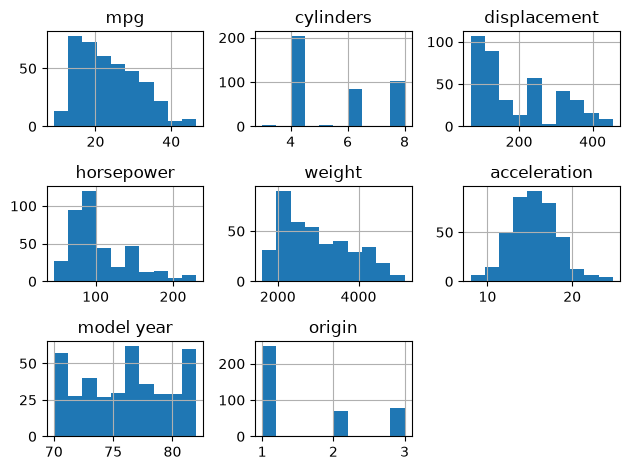

In [4]:
import matplotlib.pyplot as plt
df.hist()
plt.tight_layout()

In [5]:
df['origin'] = df['origin'].map({1:'USA',2:"Europe",3:"Asia"})
df = pd.get_dummies(df,columns=['origin'],prefix='orig',prefix_sep='_')

In [6]:
df.columns

Index(['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
       'acceleration', 'model year', 'car name', 'orig_Asia', 'orig_Europe',
       'orig_USA'],
      dtype='str')

In [7]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,car name,orig_Asia,orig_Europe,orig_USA
0,18.0,8,307.0,130.0,3504.0,12.0,70,chevrolet chevelle malibu,False,False,True
1,15.0,8,350.0,165.0,3693.0,11.5,70,buick skylark 320,False,False,True
2,18.0,8,318.0,150.0,3436.0,11.0,70,plymouth satellite,False,False,True
3,16.0,8,304.0,150.0,3433.0,12.0,70,amc rebel sst,False,False,True
4,17.0,8,302.0,140.0,3449.0,10.5,70,ford torino,False,False,True


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   car name      398 non-null    str    
 8   orig_Asia     398 non-null    bool   
 9   orig_Europe   398 non-null    bool   
 10  orig_USA      398 non-null    bool   
dtypes: bool(3), float64(5), int64(2), str(1)
memory usage: 26.2 KB


In [9]:
df[['orig_USA','orig_Europe','orig_Asia']] = df[['orig_USA','orig_Europe','orig_Asia']].astype(int)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   car name      398 non-null    str    
 8   orig_Asia     398 non-null    int64  
 9   orig_Europe   398 non-null    int64  
 10  orig_USA      398 non-null    int64  
dtypes: float64(5), int64(5), str(1)
memory usage: 34.3 KB


In [11]:
import seaborn as sns
sns.pairplot(data=df.drop(['orig_USA','orig_Europe','"orig_Asia'], axis=1))

KeyError: '[\'"orig_Asia\'] not found in axis'

In [14]:
corr = df.corr()[['mpg']]

sns.heatmap((corr.iloc[(-corr['mpg'].abs()).argsort()]),vmin=-1, vmax=1,annot=True, cmap='coolwarm')

ValueError: could not convert string to float: 'chevrolet chevelle malibu'